In [3]:
# 1. ADD THESE MISSING IMPORTS FIRST
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 2. YOUR DEEP LEARNING IMPORTS
import torch
import torch.nn as nn
from torchvision import models, transforms

# 3. YOUR IMAGE & UTILITY IMPORTS
import os
from pathlib import Path
import joblib
import time

# 4. YOUR MACHINE LEARNING IMPORTS
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics.pairwise import cosine_similarity

# 5. YOUR SETTINGS (These will now work perfectly!)
import warnings
warnings.filterwarnings("ignore")
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette('husl')

# 6. YOUR RANDOM SEEDS
np.random.seed(42)
torch.manual_seed(42)

print("All libraries imported successfully!")






All libraries imported successfully!


In [4]:
#configuration
USE_SUBSET = True
SUBSET_SIZE = 2000
BATCH_SIZE = 32


In [18]:
import pandas as pd
from pathlib import Path

# Setup dataset source
img_dir = Path("myntradatasets/myntradatasets/images")
valid_extensions = {".png", ".jpg", ".jpeg"}

# Gather valid files from the directory
img_paths = [p for p in img_dir.iterdir() if p.suffix.lower() in valid_extensions]

if img_paths:
    dataset = []
    for p in img_paths:
        dataset.append({
            "image_id": p.stem,
            "image_path": str(p),
            "filename": p.name
        })

    # Process dataframe and extract a stable random subset
    fashion_df = pd.DataFrame(dataset)
    sample_size = min(SUBSET_SIZE, len(fashion_df))

    fashion_df = fashion_df.sample(n=sample_size, random_state=42).reset_index(drop=True)
    print(fashion_df.head())
else:
    print(f"Directory empty or path does not exist: {img_dir.absolute()}")


  image_id                                      image_path   filename
0    34522  myntradatasets\myntradatasets\images\34522.jpg  34522.jpg
1     6807   myntradatasets\myntradatasets\images\6807.jpg   6807.jpg
2    20194  myntradatasets\myntradatasets\images\20194.jpg  20194.jpg
3    27865  myntradatasets\myntradatasets\images\27865.jpg  27865.jpg
4    45293  myntradatasets\myntradatasets\images\45293.jpg  45293.jpg


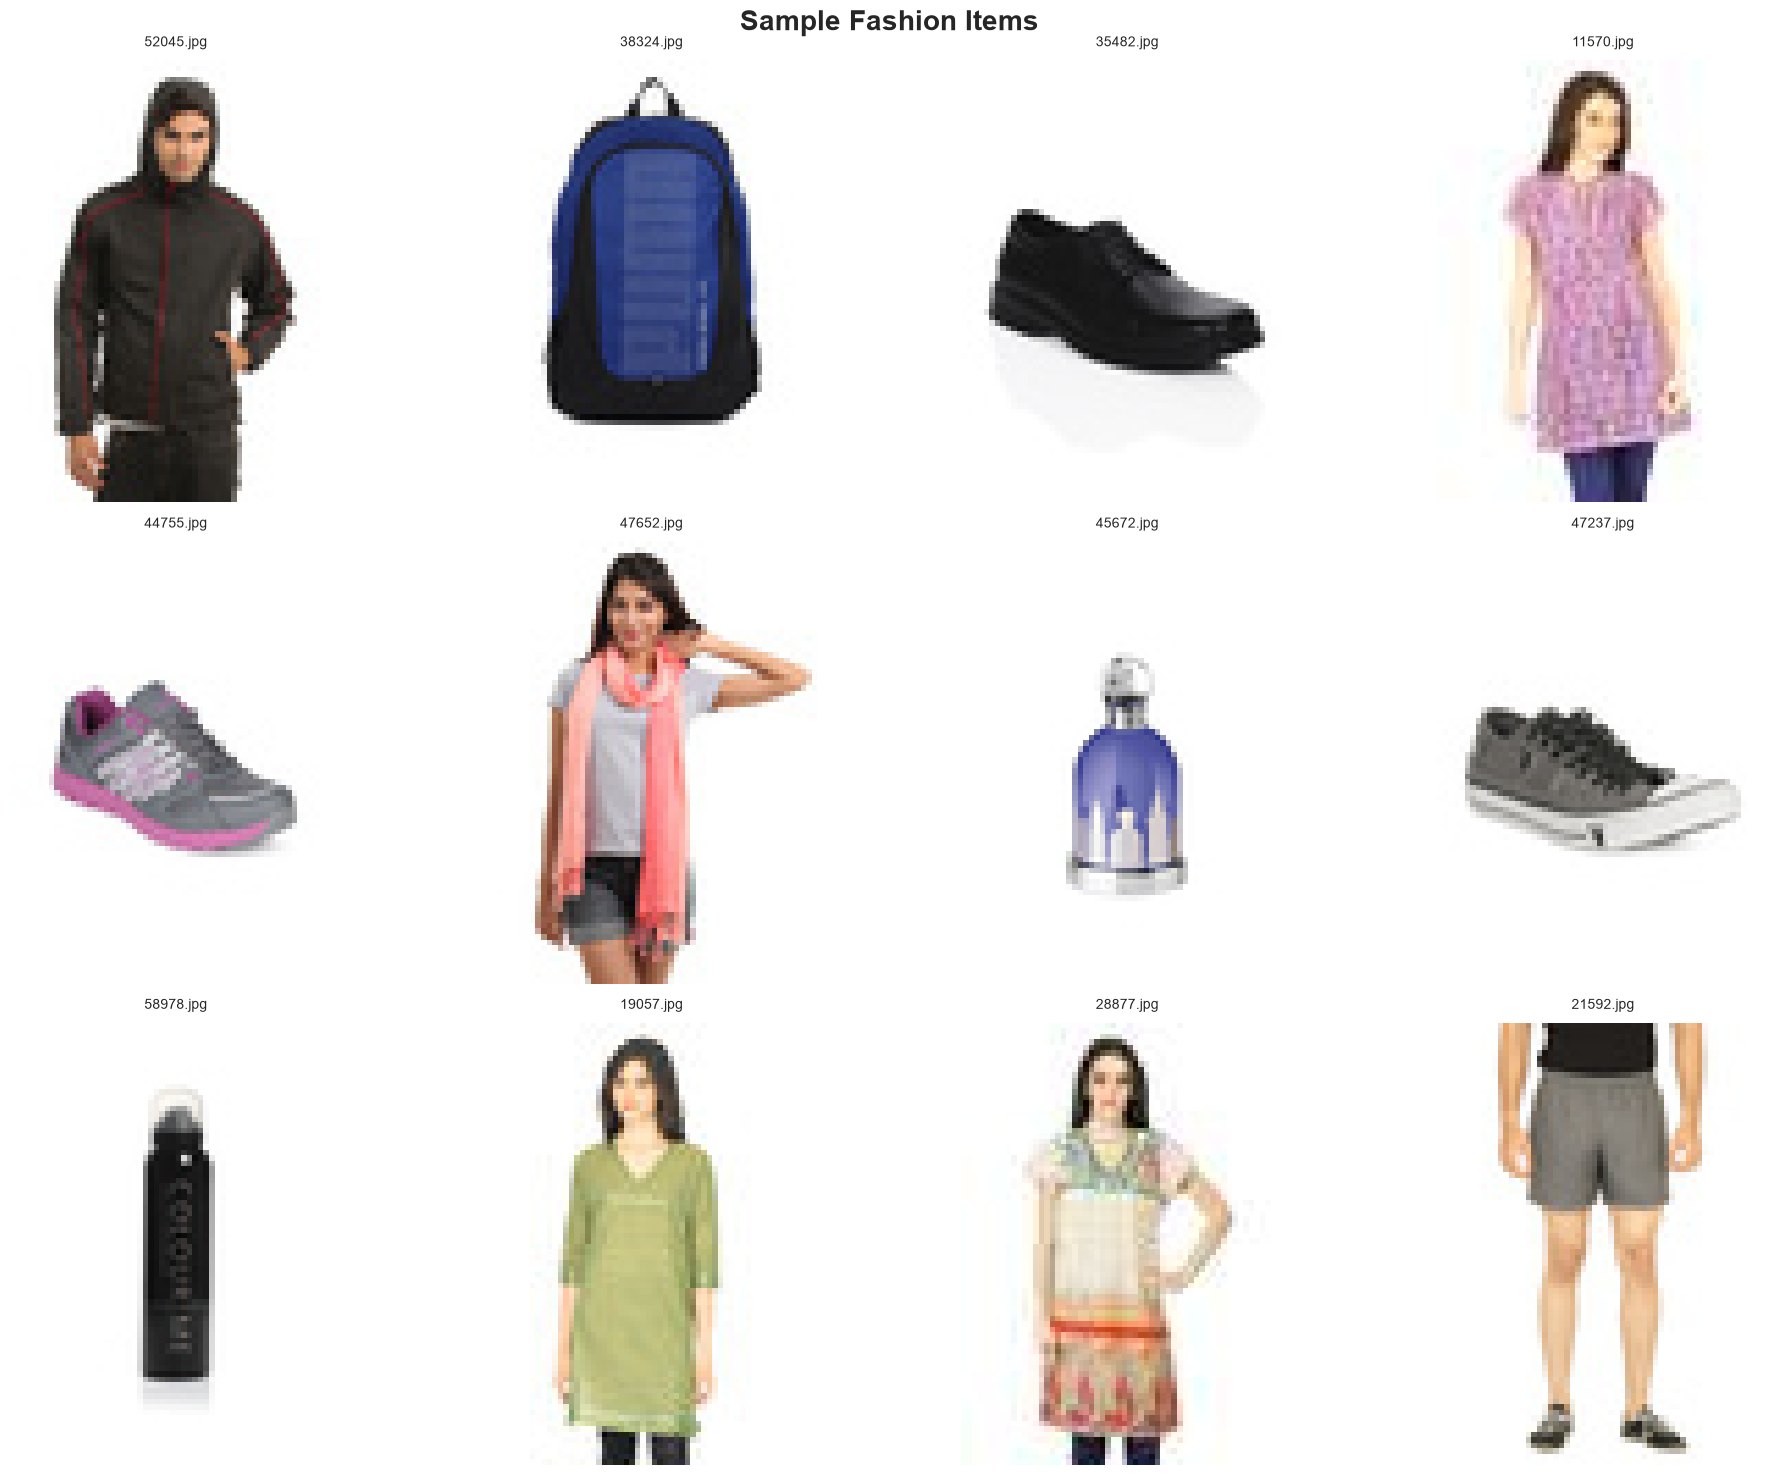

In [28]:
import matplotlib.pyplot as plt
from PIL import Image

# Initialize grid layout
fig, axes = plt.subplots(3, 4, figsize=(20, 15))
fig.suptitle('Sample Fashion Items', fontsize=20, fontweight='bold', y=0.98)

# Select random items to display
sample_items = fashion_df.sample(min(12, len(fashion_df)), random_state=42)

for idx, (ax, (_, item)) in enumerate(zip(axes.flat, sample_items.iterrows())):
    try:
        # Load and render image
        img = Image.open(item['image_path'])
        ax.imshow(img)

        # Format title cleanly
        title_text = f"{item['filename'][:20]}..." if len(item['filename']) > 20 else item['filename']
        ax.set_title(title_text, fontsize=10, pad=10)
        ax.axis('off')

    except Exception:
        # Fallback if an image fails to load
        error_text = f"Error loading\n{item['filename'][:15]}..."
        ax.text(0.5, 0.5, error_text, ha='center', va='center', color='red', fontsize=9)
        ax.axis('off')

plt.tight_layout()
plt.show()



        #display sample images





In [34]:
model = models.resnet18(pretrained = True)
model = nn.Sequential(*list(model.children())[:-1])
model = model.to('cpu')
model.eval()

transform= transforms.Compose([
    transforms.Resize((224,224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485,0.456,0.406],
    std =[0.229,0.224,0.225])

])



In [38]:
all_features = []
failed_images = []
start_time = time.time()

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = model.to(device).eval()

for i in range(0, len(fashion_df), BATCH_SIZE):
    batch_df = fashion_df.iloc[i:i + BATCH_SIZE]
    batch_images = []
    batch_indices = []

    for idx, row in batch_df.iterrows():
        try:
            with Image.open(row['image_path']) as img:
                img = img.convert('RGB')
                batch_images.append(transform(img))

            batch_indices.append(idx)

        except Exception:
            failed_images.append(row['filename'])

    if batch_images:
        batch_tensor = torch.stack(batch_images).to(
            device, non_blocking=(device.type == 'cuda')
        )

        with torch.inference_mode():
            features = model(batch_tensor)

            if features.ndim == 1:
                features = features.unsqueeze(0)

            all_features.append(features.cpu().numpy())

    processed = min(i + BATCH_SIZE, len(fashion_df))

    if processed % 200 < BATCH_SIZE or processed == len(fashion_df):
        elapsed = time.time() - start_time
        print(
            f"Progress: {processed / len(fashion_df) * 100:.1f}% | "
            f"Processed: {processed:,}/{len(fashion_df):,} | "
            f"Time: {elapsed:.1f}s"
        )

features_array = (
    np.concatenate(all_features, axis=0)
    if all_features else np.empty((0,))
)

if failed_images:
    fashion_df = fashion_df[
        ~fashion_df['filename'].isin(failed_images)
    ].reset_index(drop=True)

elapsed_time = time.time() - start_time

print(f"\nCompleted in {elapsed_time:.1f}s")
print(f"Extracted features: {len(features_array):,}")
print(f"Failed images: {len(failed_images):,}")
print(f"Device: {device}")

Progress: 11.2% | Processed: 224/2,000 | Time: 8.2s
Progress: 20.8% | Processed: 416/2,000 | Time: 15.1s
Progress: 30.4% | Processed: 608/2,000 | Time: 21.8s
Progress: 40.0% | Processed: 800/2,000 | Time: 28.6s
Progress: 51.2% | Processed: 1,024/2,000 | Time: 36.3s
Progress: 60.8% | Processed: 1,216/2,000 | Time: 43.2s
Progress: 70.4% | Processed: 1,408/2,000 | Time: 50.1s
Progress: 80.0% | Processed: 1,600/2,000 | Time: 57.1s
Progress: 91.2% | Processed: 1,824/2,000 | Time: 65.2s
Progress: 100.0% | Processed: 2,000/2,000 | Time: 71.7s

Completed in 71.7s
Extracted features: 2,000
Failed images: 0
Device: cpu


In [36]:
#Build K-Nearest Neighbors model

knn_model = NearestNeighbors(
    n_neighbors=min(20, len(features_array)),
    metric='cosine',
    algorithm='brute'
)

knn_model.fit(features_array)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",20
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'brute'
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'cosine'
,"radius radius: float, default=1.0Range of parameter space to use by default for :meth:`radius_neighbors`queries.",1.0
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float (positive), default=2Parameter for the Minkowski metric fromsklearn.metrics.pairwise.pairwise_distances. When p = 1, this isequivalent to using manhattan_distance (l1), and euclidean_distance(l2) for p = 2. For arbitrary p, minkowski_distance (l_p) is used.",2
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
Name,Type,Value
effective_metric_ effective_metric_: strMetric used to compute distances to neighbors.,str,'cosine'
effective_metric_params_ effective_metric_params_: dictParameters for the metric used to compute distances to neighbors.,dict,{}


In [40]:
n_test = min(3, len(fashion_df))

test_indices = np.random.choice(len(fashion_df), size=n_test, replace=False)

for test_num in range(n_test):
    test_idx = test_indices[test_num]
    query_item = fashion_df.iloc[test_idx]

    query_features = features_array[test_idx].reshape(1, -1)
    distances, indices = knn_model.kneighbors(
        query_features, n_neighbors=min(7, len(fashion_df))
    )

    indices = indices[0]
    distances = distances[0]

    # Remove the query item itself
    mask = indices != test_idx
    indices = indices[mask][:6]
    distances = distances[mask][:6]

    recommendations = fashion_df.iloc[indices].copy()
    recommendations['similarity'] = 1 - distances

    print(f"\nQuery Item: {query_item['filename']}")
    print("Top Recommendations")

    for i, (_, rec) in enumerate(recommendations.iterrows(), 1):
        print(
            f" {i}. {rec['filename'][:35]:35} "
            f"| Similarity: {rec['similarity']:.2%}"
        )

    print()


Query Item: 11623.jpg
Top Recommendations
 1. 10510.jpg                           | Similarity: 91.96%
 2. 26935.jpg                           | Similarity: 91.78%
 3. 14326.jpg                           | Similarity: 91.13%
 4. 20002.jpg                           | Similarity: 90.86%
 5. 32572.jpg                           | Similarity: 90.73%
 6. 5111.jpg                            | Similarity: 90.66%


Query Item: 12148.jpg
Top Recommendations
 1. 12546.jpg                           | Similarity: 92.56%
 2. 26891.jpg                           | Similarity: 92.53%
 3. 43618.jpg                           | Similarity: 91.87%
 4. 46995.jpg                           | Similarity: 91.85%
 5. 27191.jpg                           | Similarity: 90.92%
 6. 16125.jpg                           | Similarity: 90.86%


Query Item: 10137.jpg
Top Recommendations
 1. 36769.jpg                           | Similarity: 87.83%
 2. 45891.jpg                           | Similarity: 86.92%
 3. 52679.jpg  

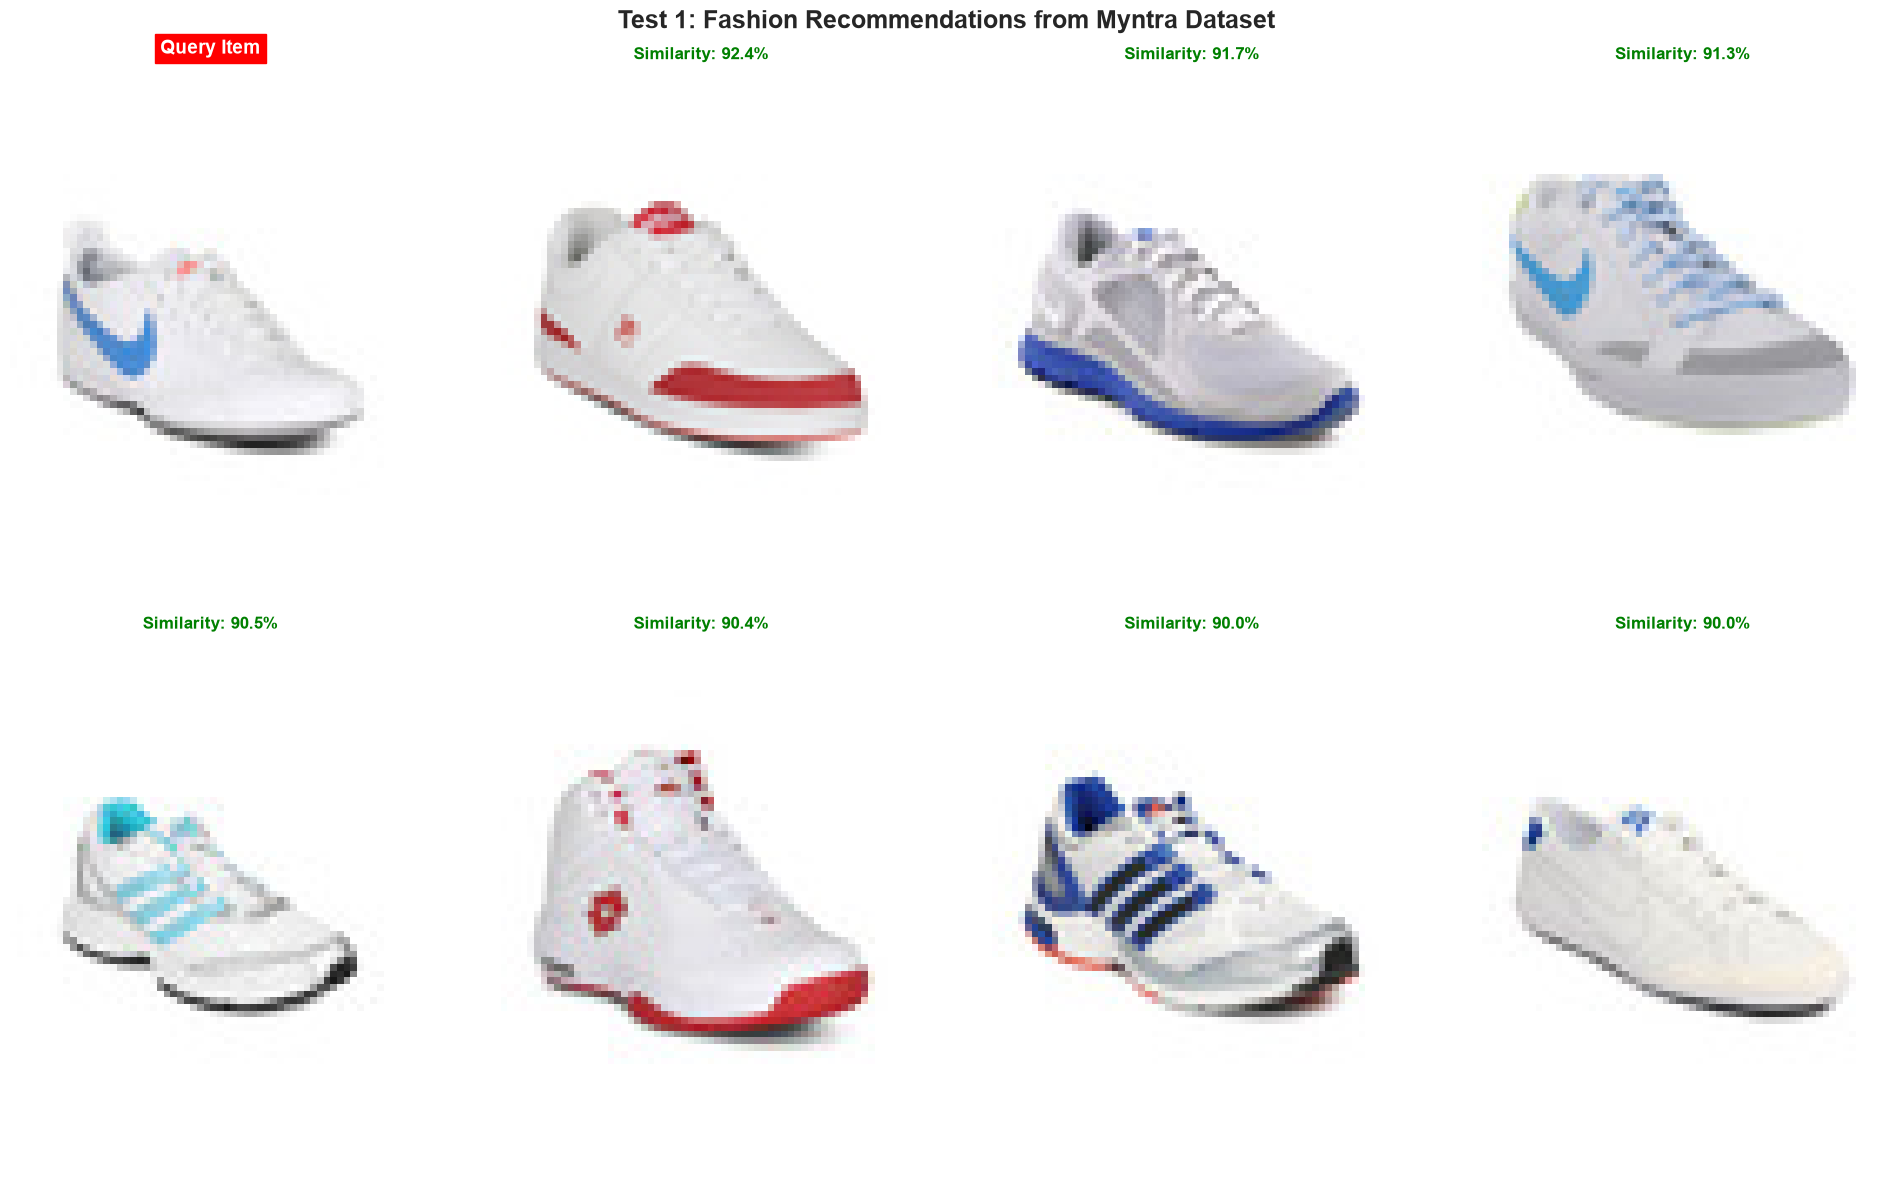

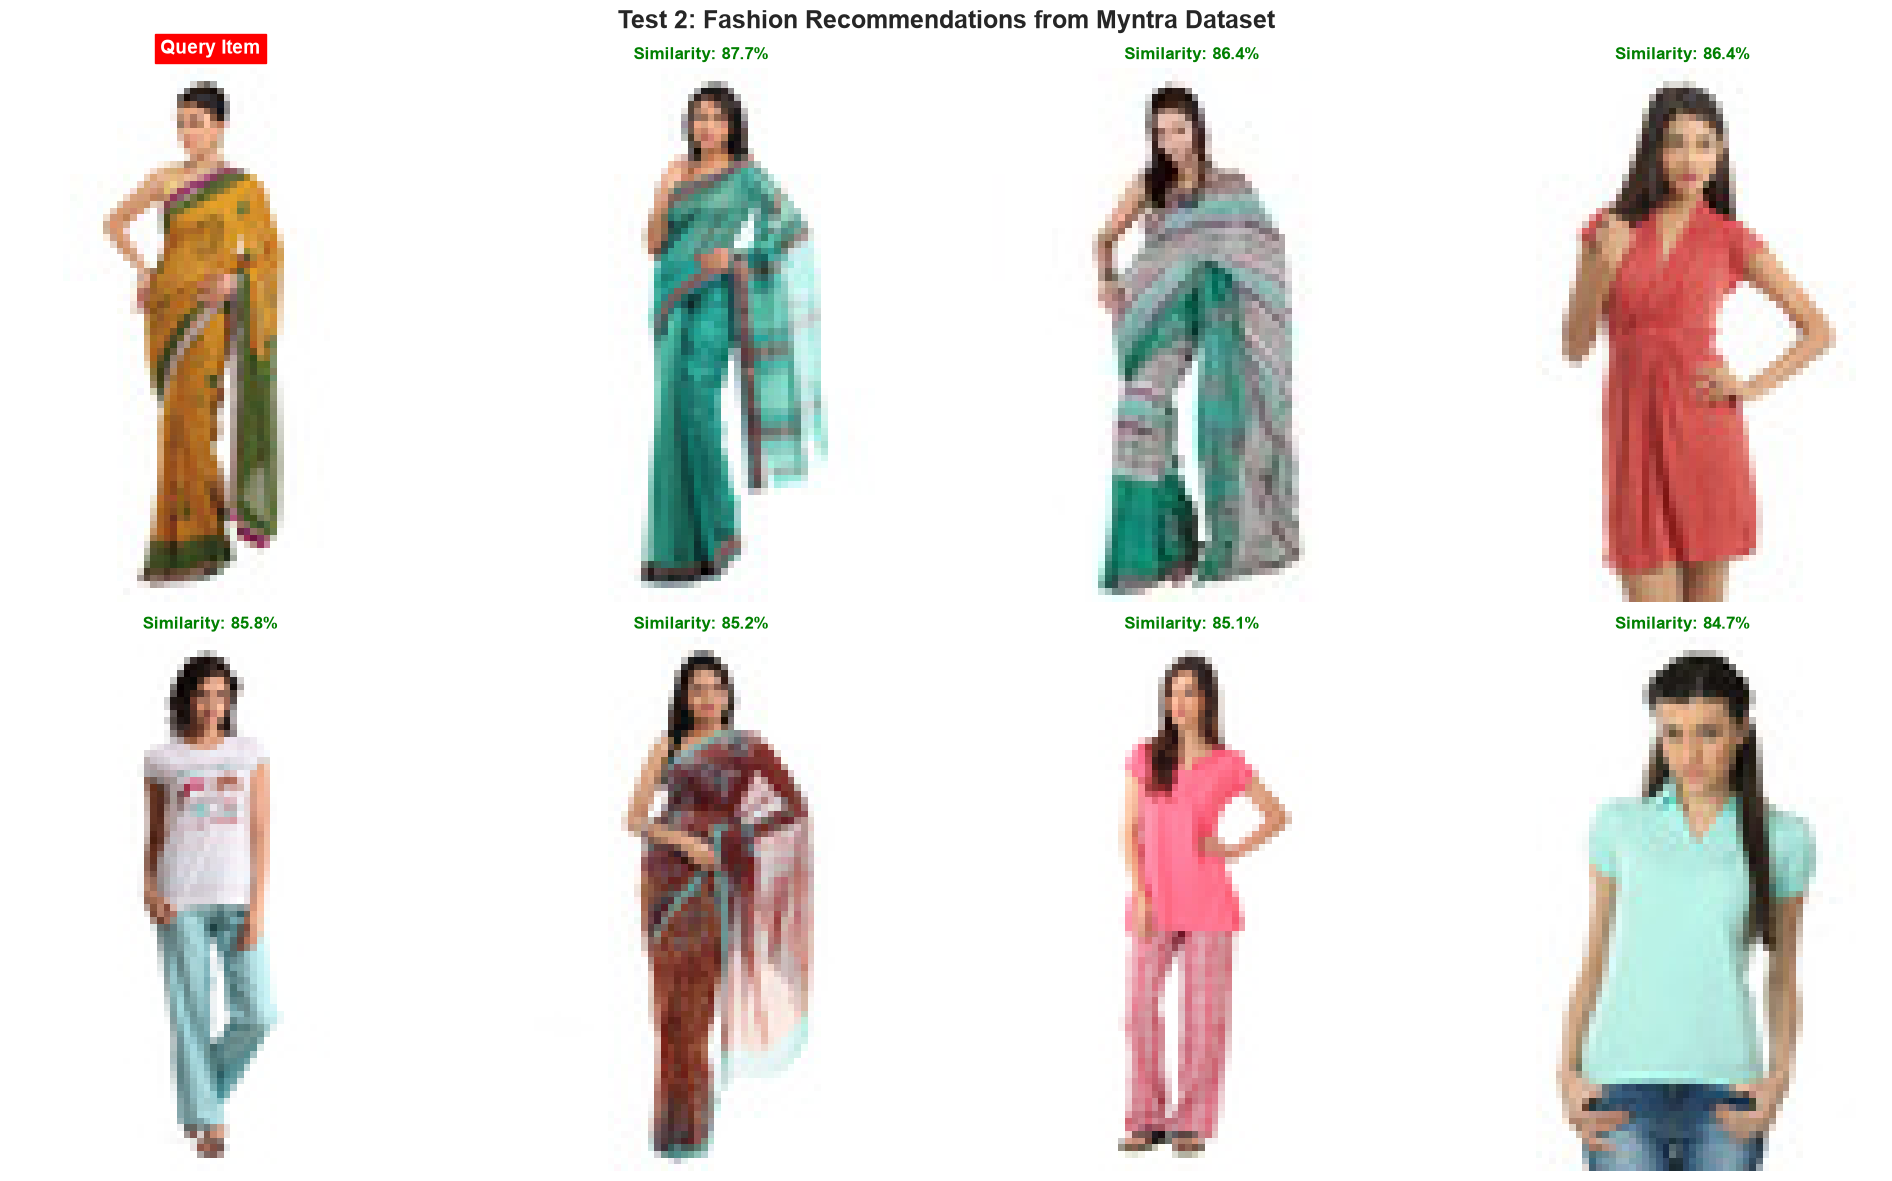

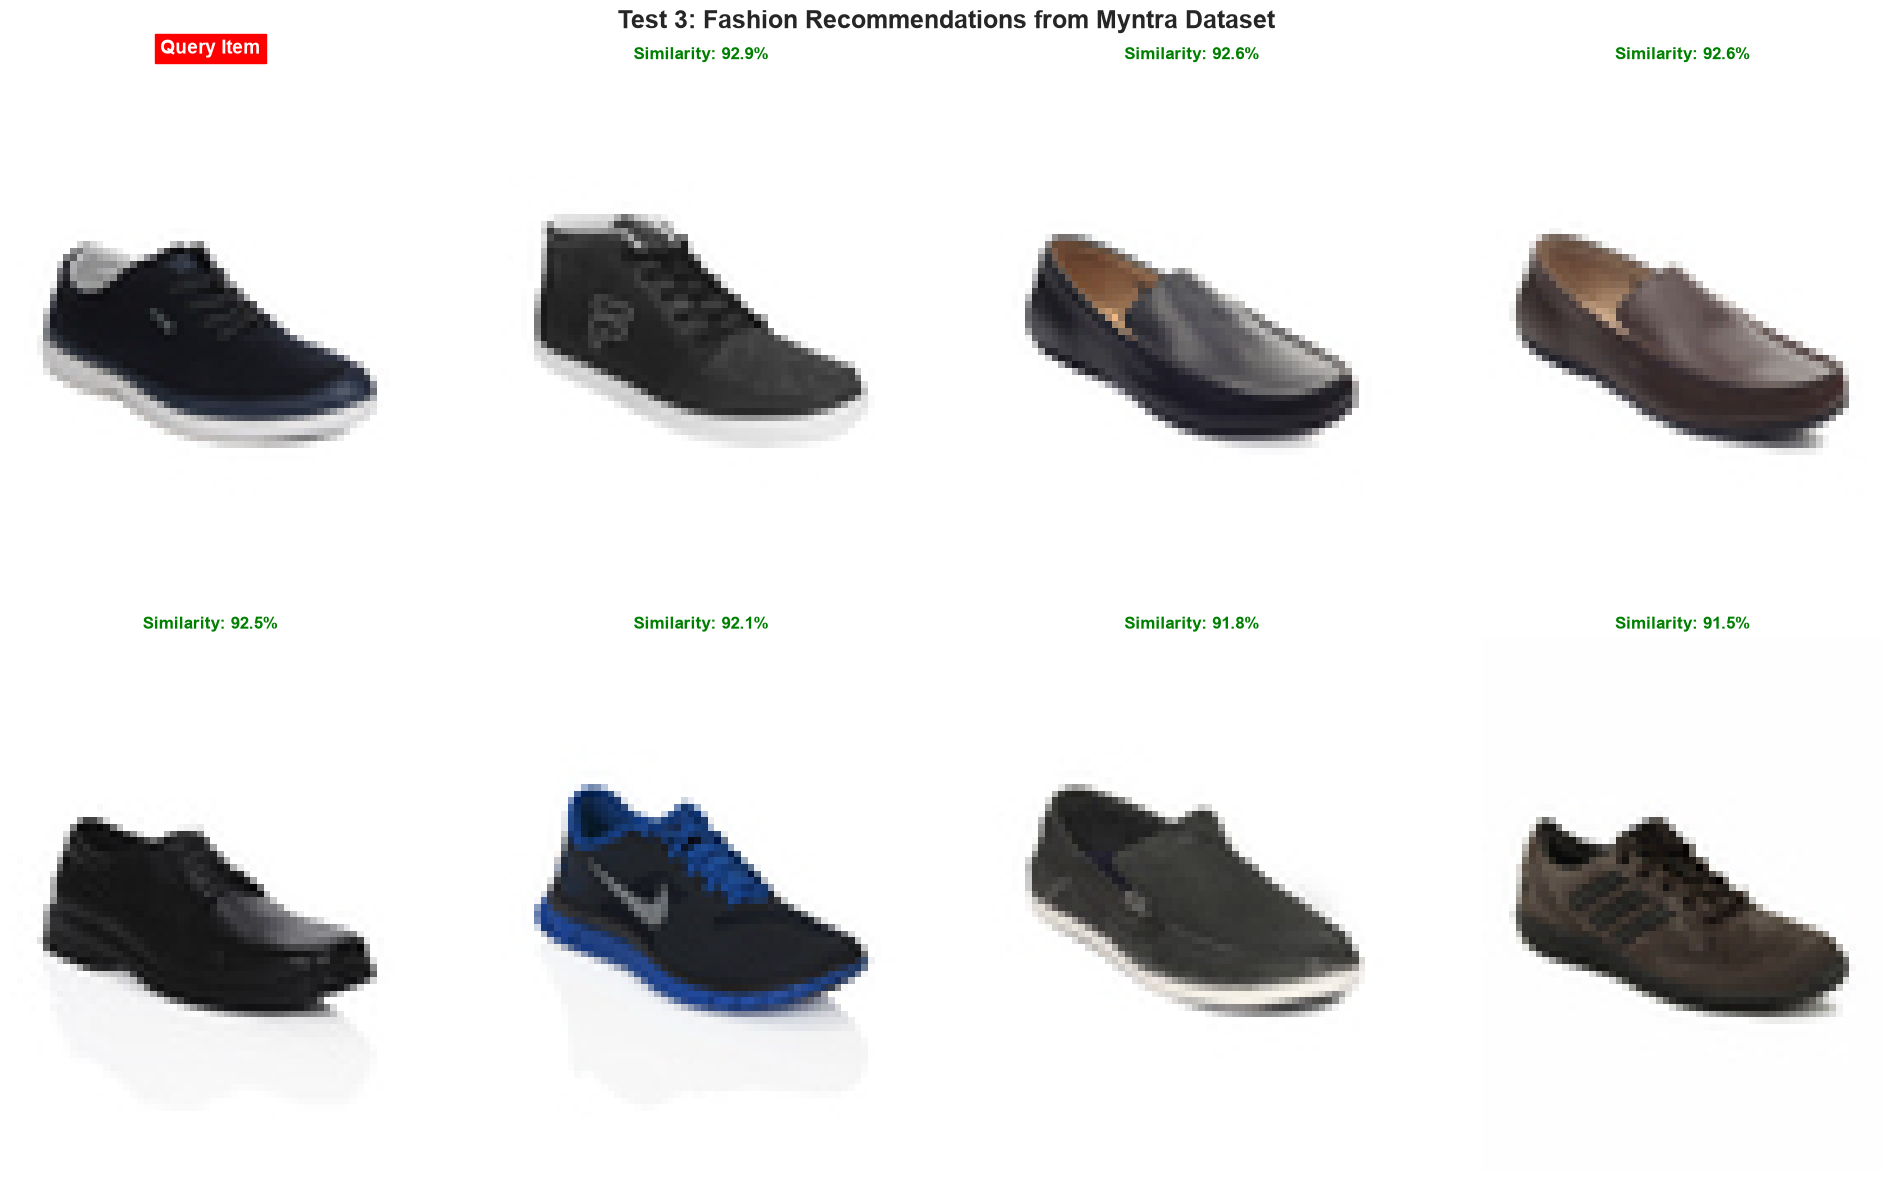

In [42]:

n_test = min(3, len(fashion_df))

test_indices = np.random.choice(
    len(fashion_df), size=n_test, replace=False
)

for test_num in range(n_test):
    test_idx = test_indices[test_num]
    query_item = fashion_df.iloc[test_idx]

    query_features = features_array[test_idx].reshape(1, -1)

    distances, indices = knn_model.kneighbors(
        query_features,
        n_neighbors=min(8, len(fashion_df))
    )

    indices = indices[0]
    distances = distances[0]

    # Remove the query item itself
    mask = indices != test_idx
    indices = indices[mask][:7]
    distances = distances[mask][:7]

    recommendations = fashion_df.iloc[indices].copy()
    recommendations['similarity'] = 1 - distances

    fig, axes = plt.subplots(2, 4, figsize=(20, 12))
    fig.suptitle(
        f"Test {test_num + 1}: Fashion Recommendations from Myntra Dataset",
        fontsize=18, fontweight='bold'
    )

    # Display query image
    try:
        with Image.open(query_item['image_path']) as query_img:
            axes[0, 0].imshow(query_img.convert('RGB'))

        axes[0, 0].set_title(
            'Query Item', fontsize=14, fontweight='bold',
            color='white', backgroundcolor='red', pad=10
        )
        axes[0, 0].axis('off')

    except Exception:
        axes[0, 0].text(
            0.5, 0.5, "Image Error", ha='center', va='center'
        )
        axes[0, 0].axis('off')

    # Display recommended items
    for ax, (_, rec) in zip(
            axes.flat[1:], recommendations.iterrows()
    ):
        try:
            with Image.open(rec['image_path']) as rec_img:
                ax.imshow(rec_img.convert('RGB'))

            ax.set_title(
                f"Similarity: {rec['similarity']:.1%}",
                fontsize=12, fontweight='bold', color='green'
            )
            ax.axis('off')

        except Exception:
            ax.text(
                0.5, 0.5, "Image Error", ha='center', va='center'
            )
            ax.axis('off')

    plt.tight_layout()
    plt.show()
    plt.close(fig)


In [46]:
os.makedirs('models',exist_ok =True)

np.save('models/fashion_features.npy', features_array)
fashion_df.to_csv('models/fashion_metadata.csv', index = False)
model_data ={
    'features': features_array,
    'metadata': fashion_df,
    'feature_extractor_type':'resnet18',
    'dataset':'myntra',
    'num_item':len(fashion_df),
    'feature_dim':features_array.shape[1]
}

joblib.dump(model_data,'models/fashion_recommender.pkl')
file_size =os.path.getsize('models/fashion_recommender.pkl')/(1024**2)


